# Capstone C2 · Bimanual ALOHA transfer-cube: scripted demonstrations → ACT on joint-space action chunks

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from vlacourse.aloha import AlohaTransfer, HandoverExpert, AlohaFilm
from vlacourse import showcase as sc
from vlacourse.chunk_policies import ACT, train_policy
from vlacourse import show_video, show_images, wilson

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
# H = 50 steps = 2 s at 25 Hz: long enough to span a whole expert phase (25 steps each, several of them pure waits).
# Measured (20 test episodes): H=20 -> 0-5/20; H=50 with 50 demos -> 14/20; H=50 with 100 demos -> 17/20.
CAMS, H, N_DEMOS = ("overhead_cam", "wrist_cam_right"), 50, 100
os.makedirs("checkpoints", exist_ok=True)

def collect(n, seed=0):
    env, eps, attempt = AlohaTransfer(cameras=CAMS, seed=seed), [], 0
    while len(eps) < n:
        # seed by ATTEMPT, not by len(eps): a failed seed would otherwise be retried forever (deterministic sim)
        k, attempt = attempt + seed * 1000, attempt + 1
        if attempt > 3 * n:
            raise RuntimeError(f"expert succeeded only {len(eps)}/{attempt - 1} times: check HandoverExpert")
        obs = env.reset(seed=k); ex = HandoverExpert(env, seed=k); rec = {c: [] for c in CAMS}; S, A = [], []; done = False
        while not done:
            a = ex.act()
            for c in CAMS:
                rec[c].append(obs["images"][c])
            S.append(obs["state"]); A.append(a)
            obs, _, done, info = env.step(a)
        if info["success"]:
            eps.append({**{c: np.array(v) for c, v in rec.items()}, "state": np.array(S), "action": np.array(A)})
    print(f"expert success: {len(eps)}/{attempt} attempts")
    return eps

class AlohaDataset(Dataset):
    def __init__(self, eps):
        self.eps = eps
        S, A = np.concatenate([e["state"] for e in eps]), np.concatenate([e["action"] for e in eps])
        self.s_mu, self.s_sd, self.a_mu, self.a_sd = S.mean(0), S.std(0) + 1e-4, A.mean(0), A.std(0) + 1e-4
        self.index = [(i, t) for i, e in enumerate(eps) for t in range(len(e["action"]))]
    def __len__(self):
        return len(self.index)
    def __getitem__(self, k):
        i, t = self.index[k]; e = self.eps[i]; T = len(e["action"]); idx = np.minimum(np.arange(t, t + H), T - 1)
        out = {"state": torch.tensor((e["state"][t] - self.s_mu) / self.s_sd, dtype=torch.float32), "task": torch.zeros(1),
               "action": torch.tensor((e["action"][idx] - self.a_mu) / self.a_sd, dtype=torch.float32)}
        for c in CAMS:
            out[c] = torch.from_numpy(e[c][t]).permute(2, 0, 1).float() / 255
        return out

@torch.no_grad()
def rollout(net, ds, seed, k=0.01, film=None, phase=""):
    """One closed-loop episode with ACT temporal ensembling. film: an AlohaFilm size (H, W) to also record a cinematic
    HD video (rendered separately; the policy only ever sees its two 96x96 cameras)."""
    env = AlohaTransfer(cameras=CAMS, seed=seed); obs = env.reset(seed=seed); hist, done, frames = [], False, []
    rec = AlohaFilm(env, size=film).begin() if film else None
    while not done:
        b = {"state": torch.tensor((obs["state"] - ds.s_mu) / ds.s_sd, dtype=torch.float32)[None], "task": torch.zeros(1, 1)}
        for c in CAMS:
            b[c] = torch.from_numpy(obs["images"][c]).permute(2, 0, 1).float()[None] / 255
        chunk = net.sample({kk: v.to(device) for kk, v in b.items()})[0].cpu().numpy() * ds.a_sd + ds.a_mu
        hist.append((env.t, chunk))
        preds = [c[env.t - s] for s, c in hist if env.t - s < H]; w = np.exp(-k * np.arange(len(preds)))
        a = np.sum([p * wi for p, wi in zip(preds, w)], 0) / w.sum()
        hist = [(s, c) for s, c in hist if env.t - s < H - 1]
        obs, _, done, info = env.step(a)
        if rec:
            rec.add(env, obs, phase)
    return info["success"], (rec.end(info["success"]) if rec else [])

expert success: 100/101 attempts
100 demonstrations, 21144 frames, 58s


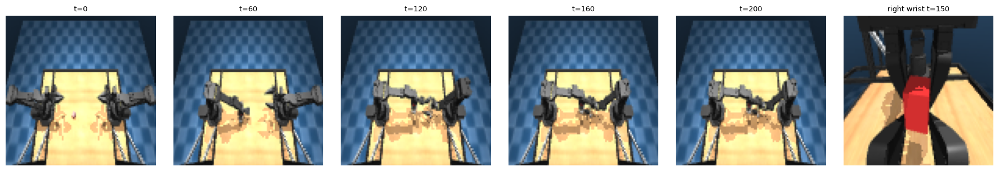

In [2]:
t0 = time.time()
eps = collect(N_DEMOS)
print(f"{len(eps)} demonstrations, {sum(len(e['action']) for e in eps)} frames, {time.time() - t0:.0f}s")
show_images([eps[0][CAMS[0]][t] for t in (0, 60, 120, 160, 200)] + [eps[0][CAMS[1]][150]], ["t=0", "t=60", "t=120", "t=160", "t=200", "right wrist t=150"], cols=6)

In [3]:
ds = AlohaDataset(eps)
net = ACT(horizon=H, act_dim=14, cameras=CAMS, state_dim=14, task_dim=1, kl_weight=10.0)
if os.path.exists("checkpoints/aloha_act.pt"):
    net.load_state_dict(torch.load("checkpoints/aloha_act.pt", map_location=device)); net.to(device)
else:
    t0 = time.time(); losses = train_policy(net, ds, epochs=60, lr=1e-4, device=device, log_every=5); torch.save(net.state_dict(), "checkpoints/aloha_act.pt")
    print(f"ACT trained in {time.time() - t0:.0f}s")
net.eval()

vlacourse/chunk_policies.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  enc = lambda: nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 8, 4 * d, 0.1, batch_first=True, norm_first=True), layers)


ACT(
  (obs): ObsEncoder(
    (backbone): ImageEncoder(
      (trunk): Sequential(
        (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
        (4): Sequential(
          (0): BasicBlock(
            (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (relu): ReLU(inplace=True)
            (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          )
          (1): BasicBlock(
            (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), b

In [4]:
t0 = time.time()
res = [rollout(net, ds, 90_000 + s)[0] for s in range(20)]
k = sum(res)
print(f"ACT bimanual transfer: {k}/20 success, Wilson 95% CI {np.round(wilson(k, 20), 2)} ({time.time() - t0:.0f}s)")

ACT bimanual transfer: 17/20 success, Wilson 95% CI [0.64 0.95] (28s)


## Share-ready video
A separate 1280×720 film camera (8× anti-aliasing, a slow orbit, 50 fps by interpolating between control steps) records
the episode; the policy itself still only sees the two 96×96 images shown in the corner. Saved to `outputs/` as H.264
(plays on LinkedIn, phones and slides).

In [5]:
hero = next(s for s in range(20) if res[s])                     # first successful test episode
ok, film = rollout(net, ds, 90_000 + hero, film=(720, 1280), phase="ACT policy · cube position never seen in training")
intro = sc.title_card("Bimanual handover with ACT", f"two ViperX arms · 2 s action chunks · 100 demonstrations\n{k}/20 successful handovers on new cube positions",
                      size=(720, 1280), n=75, footer="MuJoCo · ALOHA (Menagerie)")
show_video(intro + film, fps=50, title="C2 ALOHA handover HD", width=960)
sc.export(intro + film, "outputs/C2_aloha_handover_hd.mp4", fps=50)

saved outputs/C2_aloha_handover_hd.mp4  (9.4 MB)


['outputs/C2_aloha_handover_hd.mp4']

In [6]:
# Four new cube positions at once (640x360 each -> one 1280x720 video), successes and failures as they come
clips = [rollout(net, ds, 90_000 + s, film=(360, 640), phase=f"test episode {s + 1}")[1] for s in range(4)]
grid = sc.grid(clips, cols=2)
show_video(grid, fps=50, title="C2 ALOHA four episodes", width=960)
sc.export(grid, "outputs/C2_aloha_four_episodes.mp4", fps=50)

saved outputs/C2_aloha_four_episodes.mp4  (10.8 MB)


['outputs/C2_aloha_four_episodes.mp4']